 # Actividad 1 — Análisis exploratorio EDA

**Técnicas de Análisis Estadístico de Modelos Supervisados**
**Datos:** *Mice Protein Expression* (UCI Machine Learning Repository, id 342). Niveles de expresión de 77 proteínas
en corteza cerebral de ratones control y trisómicos (modelo de síndrome de Down), con y sin memantina, con y sin
estimulación de aprendizaje (Higuera et al., 2015).

**Objetivo del notebook:** inspeccionar, describir y preparar la base para las actividades 2 (regresión) y 3 (clasificación).

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | Carga, estructura y tamaño efectivo |
| 2 | Análisis descriptivo |
| 3 | Valores faltantes |
| 4 | Valores atípicos | 
| 5 | Relaciones entre variables |
| 6 | Base depurada |



## 0. Preparación del entorno

In [1]:
# Librerias externas
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# Paquete del proyecto: semilla, rutas y funciones de carga
from mice_supervisado.config import SEMILLA, ARCHIVO_DEPURADO, ruta_figuras
from mice_supervisado.datos import cargar_crudos, cargar_depurados

# Configuración de la sesión 
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 90)
FIGURAS = ruta_figuras(1)

## 1. Carga, estructura y tamaño efectivo

Esta sección responde tres preguntas antes de cualquier análisis: qué contiene la base, qué representa cada fila
y cuántas unidades independientes hay realmente.

In [2]:
# Lectura del archivo original de UCI sin transformaciones
df = cargar_crudos()

### 1.1 Dimensiones y tipos

In [3]:
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas\n")

# Conteo de columnas por tipo (resumen de las 82 columnas)
print(df.dtypes.value_counts())

Dimensiones: 1080 filas x 82 columnas

float64    77
str         5
Name: count, dtype: int64


### 1.2 Clasificación de columnas

In [4]:
# Las proteínas comparten el sufijo "_N" (nivel de expresión nuclear)
proteinas = [col for col in df.columns if col.endswith("_N")]
diseno = ["Genotype", "Treatment", "Behavior", "class"]
identificador = ["MouseID"]

# Verificación: las tres listas deben cubrir todas las columnas sin sobrantes
assert len(proteinas) + len(diseno) + len(identificador) == df.shape[1]
print(f"Proteínas: {len(proteinas)} | Diseño: {len(diseno)} | Identificador: {len(identificador)}")

Proteínas: 77 | Diseño: 4 | Identificador: 1


### 1.3 Valores faltantes

El análisis detallado se desarrolla en la sección 3

In [5]:
# Verificación: las variables de diseño y el identificador no tienen faltantes
assert df[diseno + identificador].notna().all().all()

# Faltantes en proteínas: proporción de celdas y de filas afectadas
total_celdas = df[proteinas].size
total_na = df[proteinas].isna().sum().sum()
filas_con_na = df[proteinas].isna().any(axis=1).sum()

print(f"Celdas faltantes: {total_na} de {total_celdas} ({total_na / total_celdas:.1%})")
print(f"Filas con al menos un faltante: {filas_con_na} de {len(df)} ({filas_con_na / len(df):.1%})")

Celdas faltantes: 1396 de 83160 (1.7%)
Filas con al menos un faltante: 528 de 1080 (48.9%)


**Interpretación:** Aunque solo el 1,7 % de las celdas de proteínas está vacío (1.396 de 83.160), casi la mitad de las filas (528 de 1.080; 48,9 %) tiene al menos un faltante. Por tanto, eliminar las filas incompletas descartaría la mitad de la base para recuperar menos del 2 % de los datos, lo que descarta esa estrategia desde el inicio y anticipa la necesidad de imputar (sección 3).

### 1.4 Unicidad y duplicados 

In [6]:
# MouseID debe identificar cada fila de forma única
print(f"¿MouseID único por fila? {df["MouseID"].is_unique}")

# Filas con valores de proteínas idénticos, aunque tengan distinto ID
print(f"Filas con proteínas idénticas: {df.duplicated(subset=proteinas).sum()}")

# Columnas de proteínas con valores idénticos en todas las filas (posible duplicado de variable)
columnas_duplicadas = df[proteinas].T.duplicated(keep=False)
print(f"Proteínas con una columna gemela: {list(columnas_duplicadas[columnas_duplicadas].index)}")

¿MouseID único por fila? True
Filas con proteínas idénticas: 0
Proteínas con una columna gemela: ['ARC_N', 'pS6_N']


**Interpretación:** Cada fila corresponde a una medición distinta y no hay filas repetidas; sin embargo, las columnas `ARC_N` y `pS6_N` son idénticas, lo que indica una duplicación en la base original y no una coincidencia biológica. Esta duplicación se trata en las secciones 3.6 y 6.4.

### 1.5 Columnas raton y replica

`MouseID` tiene la forma `<ratón>_<réplica>`: cada ratón se midió varias veces. Separar ambas partes permite
identificar al individuo, que es la unidad independiente del estudio.

In [7]:
# rsplit con n=1 corta solo en el último "_", de modo que la réplica siempre queda a la derecha
df[["raton", "replica"]] = df["MouseID"].str.rsplit("_", n=1, expand=True)
df["replica"] = df["replica"].astype(int)

df[["MouseID", "raton", "replica"]].head()

,MouseID,raton,replica
0,309_1,309,1
1,309_2,309,2
2,309_3,309,3
3,309_4,309,4
4,309_5,309,5


### 1.6 Verificación de raton

In [8]:
# Cada ratón pertenece a una sola clase; de lo contrario "raton" no identificaría individuos
clases_por_raton = df.groupby("raton")["class"].nunique()
print(f"Ratones asignados a más de una clase: {(clases_por_raton > 1).sum()}")

Ratones asignados a más de una clase: 0


### 1.7 Mediciones por ratón

In [9]:
mediciones = df["raton"].value_counts()

print(f"Ratones distintos: {df['raton'].nunique()}")
print(f"Mediciones por ratón: mín {mediciones.min()}, máx {mediciones.max()}")

# Distribución: cuántos ratones tienen cada número de mediciones
print(mediciones.value_counts().rename("n_ratones"))

Ratones distintos: 72
Mediciones por ratón: mín 15, máx 15
count
15    72
Name: n_ratones, dtype: int64


### 1.8 Tamaño efectivo por clase

El tamaño efectivo es el número de ratones, no el de filas: las réplicas de un mismo ratón no son observaciones
independientes (ver sección 2.3).

In [10]:
# Ratones distintos (tamaño efectivo) frente a filas (mediciones) por clase
resumen_clases = (
    df.groupby("class")
    .agg(ratones=("raton", "nunique"), filas=("MouseID", "size"))
    .sort_index()
)

resumen_clases.loc["Total"] = resumen_clases.sum()
resumen_clases

,ratones,filas
class,,
c-CS-m,10,150
c-CS-s,9,135
c-SC-m,10,150
c-SC-s,9,135
t-CS-m,9,135
t-CS-s,7,105
t-SC-m,9,135
t-SC-s,9,135
Total,72,1080


**Interpretación:** Los 72 ratones tienen exactamente 15 réplicas cada uno, de modo que las 1.080 filas no son 1.080 observaciones independientes, sino 72 individuos medidos repetidamente. En consecuencia, el tamaño efectivo por clase es de 7 a 10 ratones, con `t-CS-s` como la clase más pequeña (7 ratones). Aunque las clases están razonablemente balanceadas en filas (entre 105 y 150), cualquier evaluación de modelos debe partir los datos por ratón y no por fila, ya que de lo contrario las réplicas de un mismo individuo quedarían a la vez en entrenamiento y en validación (sección 2.3).

## 2. Análisis descriptivo

### 2.1 Medidas de tendencia central, dispersión y forma

Se usa el coeficiente de variación (CV = desviación estándar / media) para comparar la variabilidad entre proteínas
con escalas distintas. Es aplicable porque los niveles de expresión son positivos y tienen cero absoluto, condición
necesaria para que el CV tenga sentido (Abdi, 2010).

In [11]:
def rango(x):
    """Rango: máximo menos mínimo"""
    return x.max() - x.min()

def iqr(x):
    """Rango intercuartílico: percentil 75 menos percentil 25"""
    return x.quantile(0.75) - x.quantile(0.25)

def cv(x):
    """Coeficiente de variación: desviación estándar relativa a la media"""
    return x.std() / x.mean()

# Una fila por proteína; los NaN se ignoran, por eso "count" varía entre proteínas
# "kurt" es el exceso de curtosis (distribución normal = 0)
resumen = (
    df[proteinas].agg(
    ["count", "mean", "median", "std", "min", "max", rango, iqr, "skew", "kurt", cv])
    .T
)

print("Proteínas con mayor coeficiente de variación")
display(resumen.nlargest(10, "cv").round(3))

print("Proteínas con menor coeficiente de variación")
display(resumen.nsmallest(10, "cv").round(3))

Proteínas con mayor coeficiente de variación


,count,mean,median,std,min,max,rango,iqr,skew,kurt,cv
AcetylH3K9_N,1080.0,0.216,0.150,0.185,0.053,1.459,1.407,0.166,2.682,8.964,0.856
pERK_N,1077.0,0.546,0.444,0.345,0.149,3.567,3.418,0.326,3.835,22.407,0.633
DYRK1A_N,1077.0,0.426,0.366,0.249,0.145,2.516,2.371,0.200,4.357,27.351,0.586
BRAF_N,1077.0,0.379,0.327,0.216,0.144,2.133,1.990,0.149,4.548,28.226,0.572
SOD1_N,1077.0,0.543,0.444,0.281,0.217,1.873,1.656,0.376,1.301,1.683,0.517
ITSN1_N,1077.0,0.617,0.566,0.252,0.245,2.603,2.357,0.225,3.622,21.518,0.408
pP70S6_N,1077.0,0.394,0.378,0.156,0.131,1.129,0.998,0.200,0.900,1.713,0.396
pCAMKII_N,1077.0,3.537,3.327,1.295,1.344,7.464,6.120,2.002,0.548,-0.579,0.366
H3AcK18_N,900.0,0.170,0.158,0.059,0.080,0.480,0.400,0.072,1.757,4.915,0.350
pPKCG_N,1080.0,1.707,1.665,0.578,0.599,3.382,2.783,0.816,0.251,-0.501,0.339


Proteínas con menor coeficiente de variación


,count,mean,median,std,min,max,rango,iqr,skew,kurt,cv
ERBB4_N,1080.0,0.156,0.156,0.015,0.100,0.209,0.108,0.018,-0.031,0.580,0.096
P3525_N,1080.0,0.291,0.291,0.030,0.207,0.444,0.236,0.042,0.184,0.139,0.103
BAX_N,1080.0,0.179,0.181,0.019,0.072,0.241,0.169,0.023,-0.591,1.406,0.105
GFAP_N,1080.0,0.121,0.120,0.013,0.086,0.214,0.128,0.015,0.862,3.952,0.109
pGSK3B_Tyr216_N,1080.0,0.849,0.850,0.094,0.577,1.205,0.627,0.122,-0.109,0.050,0.111
PSD95_N,1080.0,2.235,2.242,0.254,1.206,2.878,1.672,0.341,-0.454,0.484,0.114
ARC_N,1080.0,0.122,0.122,0.014,0.067,0.159,0.091,0.021,-0.078,-0.381,0.117
pS6_N,1080.0,0.122,0.122,0.014,0.067,0.159,0.091,0.021,-0.078,-0.381,0.117
pGSK3B_N,1080.0,0.161,0.160,0.019,0.100,0.253,0.153,0.022,0.543,1.348,0.120
CDK5_N,1080.0,0.292,0.294,0.037,0.181,0.817,0.636,0.040,2.485,35.446,0.128


**Interpretación:** Las proteínas más variables (`AcetylH3K9_N`, CV = 0,86; `pERK_N`, 0,63; `DYRK1A_N`, 0,59; `BRAF_N`, 0,57) tienen una media claramente mayor que la mediana y un máximo muy alejado del resto; por ejemplo, `pERK_N` alcanza 3,57 con una mediana de 0,44. Esto indica que su variabilidad proviene de colas largas hacia valores altos más que de una dispersión homogénea, lo que se examina en las secciones 2.2 y 4. En el otro extremo, proteínas como `ERBB4_N`, `BAX_N` o `GFAP_N` tienen un CV cercano a 0,10 y, por ende, varían poco entre condiciones. Cabe señalar que el CV no capta todo: `CDK5_N` tiene un CV bajo (0,13), pero una curtosis de 35, lo que revela unos pocos valores extremos dentro de una distribución por lo demás estable. Por último, las escalas difieren mucho entre proteínas (la media de `pCAMKII_N` es 3,54 y la de `ARC_N`, 0,12), por lo que los métodos basados en distancias, como la imputación con k vecinos, requieren escalar las variables antes de aplicarse (James et al., 2023).

### 2.2 Forma de las distribuciones

Criterio: |asimetría| < 0,5 se considera aproximadamente simétrica, entre 0,5 y 1 moderada, y > 1 fuerte
(Bulmer, 1979). En este análisis se reportan las proteínas con asimetría fuerte.

In [12]:
UMBRAL_ASIMETRIA = 1

fuerte = resumen["skew"].abs() > UMBRAL_ASIMETRIA
derecha = resumen["skew"] > UMBRAL_ASIMETRIA
izquierda = resumen["skew"] < -UMBRAL_ASIMETRIA

print(f"Asimetría fuerte: {fuerte.sum()} de {len(resumen)} proteínas")
print(f"  a la derecha: {derecha.sum()} | a la izquierda: {izquierda.sum()}")

# Detalle de las proteínas con asimetría fuerte, de mayor a menor
asimetria_fuerte = resumen.loc[fuerte, ["skew", "kurt", "cv"]].sort_values("skew", ascending=False).round(3)
asimetria_fuerte

Asimetría fuerte: 17 de 77 proteínas
  a la derecha: 17 | a la izquierda: 0


,skew,kurt,cv
GluR4_N,4.739,62.549,0.212
BRAF_N,4.548,28.226,0.572
DYRK1A_N,4.357,27.351,0.586
RRP1_N,4.004,46.118,0.191
pELK_N,3.995,25.655,0.327
pERK_N,3.835,22.407,0.633
ITSN1_N,3.622,21.518,0.408
AcetylH3K9_N,2.682,8.964,0.856
CDK5_N,2.485,35.446,0.128
Tau_N,1.867,4.575,0.328


**Interpretación:** Las 17 proteínas con asimetría fuerte son todas asimétricas a la derecha, y varias tienen además una curtosis muy alta (`GluR4_N`: 62,5; `RRP1_N`: 46,1). En otras palabras, la mayoría de los ratones presenta niveles similares, mientras que unos pocos tienen niveles mucho mayores. Este patrón coincide con las proteínas de mayor CV de la sección 2.1, lo que confirma que su variabilidad se concentra en la cola derecha.

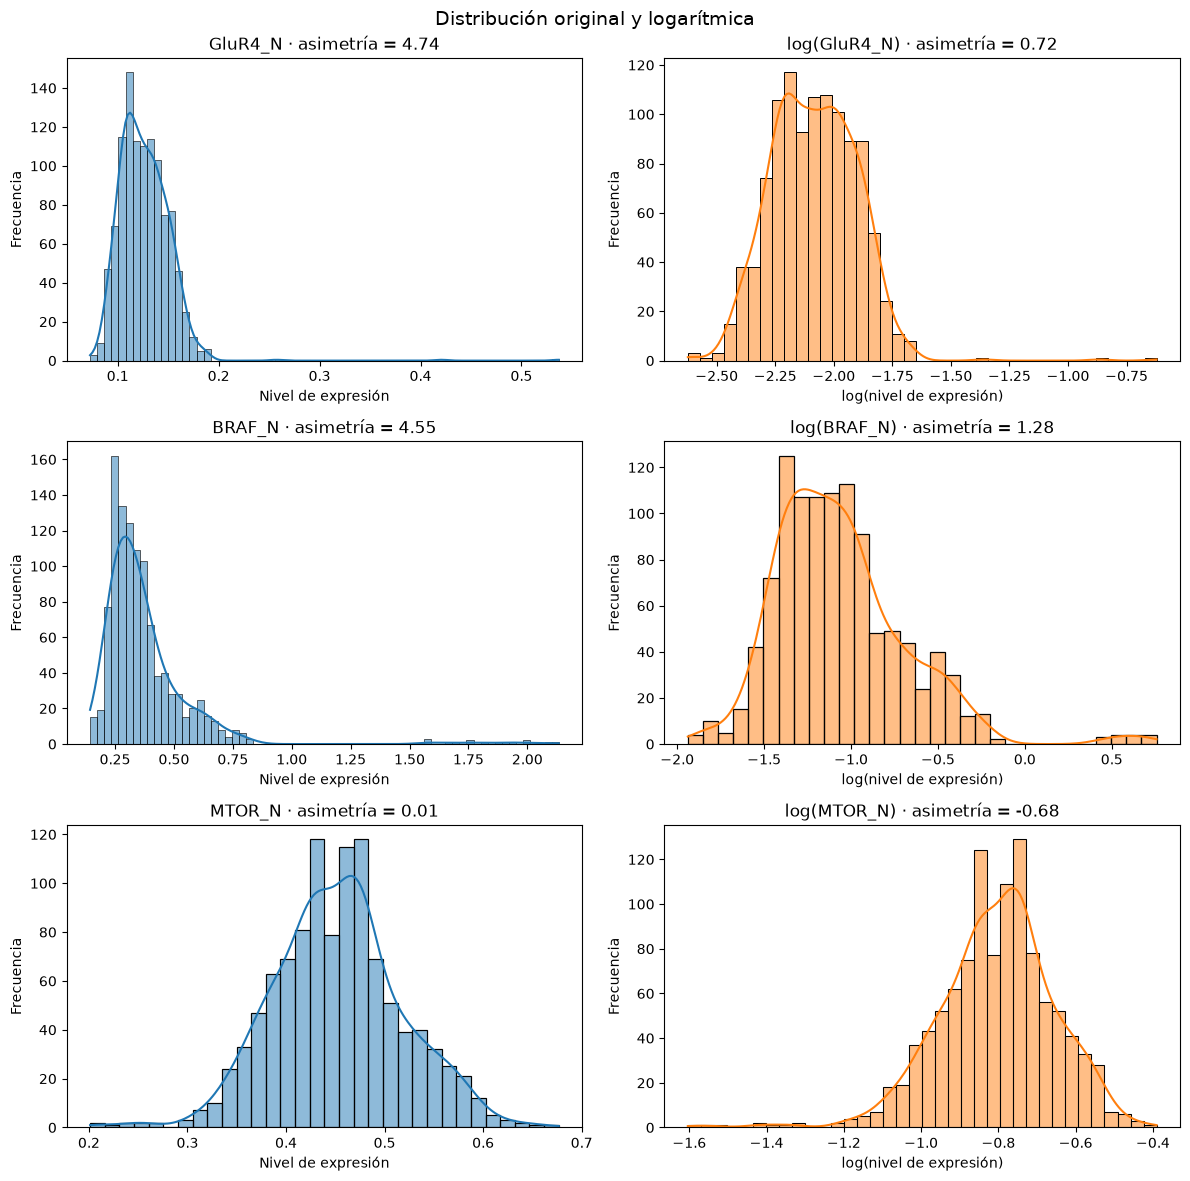

In [13]:
# Dos proteínas con asimetría fuerte y la más simétrica, como contraste
proteinas_hist = list(asimetria_fuerte.head(2).index) + [resumen["skew"].abs().idxmin()]

fig, axs = plt.subplots(len(proteinas_hist), 2, figsize=(12, 4 * len(proteinas_hist)))

for (ax_orig, ax_log), proteina in zip(axs, proteinas_hist):
    valores = df[proteina].dropna()
    valores_log = np.log(valores)

    # Escala original
    sns.histplot(valores, kde=True, ax=ax_orig)
    ax_orig.set(title=f"{proteina} · asimetría = {valores.skew():.2f}",
                xlabel="Nivel de expresión", ylabel="Frecuencia")

    # Escala logarítmica
    sns.histplot(valores_log, kde=True, color="tab:orange", ax=ax_log)
    ax_log.set(title=f"log({proteina}) · asimetría = {valores_log.skew():.2f}",
               xlabel="log(nivel de expresión)", ylabel="Frecuencia")

fig.suptitle("Distribución original y logarítmica", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS / "histogramas_asimetria.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** La transformación logarítmica reduce la asimetría de `GluR4_N` de 4,74 a 0,72, pero en `BRAF_N` solo la lleva de 4,55 a 1,28 y deja visible un grupo de valores separado del resto. Esto indica que la asimetría de `BRAF_N` no se debe solo a la escala de medición, sino a un subgrupo de observaciones con niveles altos, que la sección 4 identifica como un ratón concreto. Por otra parte, en `MTOR_N`, que ya era simétrica, el logaritmo introduce una asimetría a la izquierda (−0,68). En consecuencia, la transformación logarítmica no conviene aplicarse a todas las proteínas por igual, y la decisión se deja para la etapa de modelado de la Actividad 2, según la variable y el modelo.

### 2.3 Variabilidad dentro de cada ratón frente a variabilidad entre ratones

Para cada proteína se comparan dos dispersiones:

- **dentro:** desviación estándar de las réplicas de cada ratón, promediada sobre los 72 ratones (ruido de medición).
- **entre:** desviación estándar de las medias de los 72 ratones (diferencias entre individuos y clases).

**Valor de referencia.** Si no hubiera diferencias reales entre ratones, la media de cada ratón variaría solo por
el ruido de sus *n* réplicas. El error estándar de una media muestral es σ/√n (James et al., 2023), de modo que con
*n* = 15 la razón entre/dentro esperada sería ≈ 1/√15 ≈ 0,26. Una razón claramente mayor que ese valor indica un
efecto de ratón; una razón mayor que 1 indica un efecto fuerte.

In [14]:
por_raton = df.groupby("raton")[proteinas]

variabilidad = pd.DataFrame({
    "dentro": por_raton.std().mean(),
    "entre": por_raton.mean().std(),
})
variabilidad["razon"] = variabilidad["entre"] / variabilidad["dentro"]

# Razón esperada si toda la variación fuera ruido de medición (sin efecto de ratón)
referencia = 1 / np.sqrt(mediciones.median())

efecto_fuerte = variabilidad["razon"] > 1
efecto_moderado = variabilidad["razon"].between(referencia, 1, inclusive="right")
sin_efecto = variabilidad["razon"] <= referencia

print(f"Razón de referencia sin efecto de ratón: {referencia:.2f}")
print(f"Mediana de la razón: {variabilidad['razon'].median():.2f}")
print(f"Efecto de ratón fuerte (razón > 1): {efecto_fuerte.sum()} de {len(variabilidad)}")
print(f"Efecto moderado ({referencia:.2f} < razón ≤ 1): {efecto_moderado.sum()}")
print(f"Sin efecto aparente (razón ≤ {referencia:.2f}): {sin_efecto.sum()}")

# Proteínas con razón ≤ 1, de menor a mayor
variabilidad.loc[~efecto_fuerte].sort_values("razon").round(3)

Razón de referencia sin efecto de ratón: 0.26
Mediana de la razón: 1.74
Efecto de ratón fuerte (razón > 1): 66 de 77
Efecto moderado (0.26 < razón ≤ 1): 11
Sin efecto aparente (razón ≤ 0.26): 0


,dentro,entre,razon
ELK_N,0.265,0.184,0.696
Bcatenin_N,0.351,0.261,0.743
pCFOS_N,0.017,0.015,0.887
BAD_N,0.021,0.019,0.900
P70S6_N,0.123,0.115,0.941
pNR1_N,0.085,0.080,0.947
NR2A_N,0.676,0.643,0.950
BAX_N,0.013,0.013,0.958
NUMB_N,0.021,0.020,0.974
pNR2B_N,0.191,0.187,0.980


**Interpretación:** Ninguna proteína tiene una razón entre/dentro cercana al valor de referencia de 0,26; por el contrario, la mediana es 1,74 y 66 de las 77 proteínas superan 1. Esto significa que, para casi todas las proteínas, las diferencias entre ratones son mucho mayores que el ruido entre las réplicas de un mismo ratón, de modo que dos réplicas del mismo individuo se parecen más entre sí que a las de otro. Por esta razón, las réplicas no son observaciones independientes y la validación de los modelos debe agrupar por ratón (Roberts et al., 2017). Además, entre las 11 proteínas con efecto moderado están `pNR1_N`, `pNR2B_N`, `NR2A_N`, `ERK_N`, `ELK_N` y `Bcatenin_N`, y `NR1_N` queda justo por encima del límite (razón = 1,03). Se trata, por tanto, de proteínas del receptor NMDA y la vía ERK con mayor variación entre réplicas, lo que explica por qué sus correlaciones disminuyen al calcularlas con promedios por ratón (secciones 5.2 y 5.5).

## 3. Valores faltantes

Esta sección cuantifica los faltantes por proteína, por ratón y por clase, con el fin de determinar si ocurren
al azar o siguen un patrón. Esa distinción define cómo tratarlos: los métodos de imputación habituales suponen
que el mecanismo que genera los faltantes no depende de información no observada (Little & Rubin, 2019).

### 3.1 Faltantes por proteína

In [15]:
# Matriz booleana de faltantes en proteínas; se reutiliza en toda la sección
na = df[proteinas].isna()

na_proteina = pd.DataFrame({
    "n_faltantes": na.sum(),
    "pct_faltantes": (na.mean() * 100).round(2),
})
na_proteina = na_proteina[na_proteina["n_faltantes"] > 0].sort_values("n_faltantes", ascending=False)

print(f"Proteínas con al menos un faltante: {len(na_proteina)} de {len(proteinas)}")
na_proteina

Proteínas con al menos un faltante: 49 de 77


,n_faltantes,pct_faltantes
BCL2_N,285,26.39
H3MeK4_N,270,25.00
BAD_N,213,19.72
EGR1_N,210,19.44
H3AcK18_N,180,16.67
pCFOS_N,75,6.94
ELK_N,18,1.67
Bcatenin_N,18,1.67
MEK_N,7,0.65
ITSN1_N,3,0.28


**Interpretación:** Aunque 49 de las 77 proteínas tienen algún faltante, el problema se concentra en seis: `BCL2_N` (26,4 %), `H3MeK4_N` (25,0 %), `BAD_N` (19,7 %), `EGR1_N` (19,4 %), `H3AcK18_N` (16,7 %) y `pCFOS_N` (6,9 %). De las demás, 40 tienen exactamente 3 faltantes, lo que sugiere que provienen de las mismas tres filas; la sección 3.2 confirma que corresponden a tres réplicas del ratón 3426. Las únicas excepciones son `ELK_N` y `Bcatenin_N` (18 cada una, es decir, esas 3 más un ratón completo) y `MEK_N` (7).

### 3.2 Faltantes por ratón

Para cada ratón se cuentan las filas afectadas, las celdas faltantes y las **proteínas ausentes**: proteínas que
faltan en todas las réplicas del ratón. Una proteína ausente no puede recuperarse a partir de las demás réplicas
del mismo individuo.

In [16]:
def faltantes_por_grupo(data, columnas, grupo):
    """Resume los faltantes de `columnas` para cada nivel de `grupo`.

    - filas_con_na: filas del grupo con al menos un faltante.
    - total_na: celdas faltantes en el grupo.
    - pct_celdas_na: porcentaje de celdas faltantes respecto al total del grupo.
    - proteinas_ausentes: columnas que faltan en todas las filas del grupo.
    """
    na_grupo = data[columnas].isna().groupby(data[grupo])

    resumen = pd.DataFrame({
        "filas_con_na": data[columnas].isna().any(axis=1).groupby(data[grupo]).sum(),
        "total_na": na_grupo.sum().sum(axis=1),
        "pct_celdas_na": (na_grupo.mean().mean(axis=1) * 100).round(2),
        "proteinas_ausentes": na_grupo.all().sum(axis=1),
    })
    return resumen[resumen["total_na"] > 0].sort_values("total_na", ascending=False)

In [17]:
na_raton = faltantes_por_grupo(df, proteinas, "raton")

print(f"Ratones con al menos un faltante: {len(na_raton)} de {df['raton'].nunique()}")
na_raton

Ratones con al menos un faltante: 36 de 72


,filas_con_na,total_na,pct_celdas_na,proteinas_ausentes
raton,,,,
3426,3,129,11.17,0
50810F,15,75,6.49,5
3479,15,64,5.54,4
322,15,60,5.19,4
3605,15,60,5.19,4
3424,15,60,5.19,4
3417,15,60,5.19,4
3418,15,60,5.19,4
3420,15,60,5.19,4


**Interpretación:** La mitad de los ratones (36 de 72) tiene algún faltante, pero el patrón no es disperso. Salvo el ratón 3426, todos los ratones afectados tienen faltantes en sus 15 réplicas, y casi siempre en múltiplos de 15; es decir, a cada ratón le falta la proteína completa y no mediciones sueltas. Los únicos faltantes parciales fuera del 3426 son 3 réplicas de `BAD_N` en el ratón 365 y 4 de `MEK_N` en el 3479. El ratón 3426 muestra el patrón opuesto: 129 faltantes concentrados en solo 3 réplicas, sin ninguna proteína ausente en todas sus mediciones. Se trata, por tanto, de dos mecanismos distintos, que se tratan por separado en la sección 3.6.

### 3.3 Faltantes por clase

Las clases tienen tamaños distintos (entre 105 y 150 filas), por lo que se comparan con el porcentaje de celdas
faltantes y no con el total.

In [18]:
# "proteinas_ausentes" no aplica a nivel de clase: se reemplaza por el conteo de ratones afectados
na_clase = faltantes_por_grupo(df, proteinas, "class").drop(columns="proteinas_ausentes")
na_clase["ratones_con_na"] = df[df["raton"].isin(na_raton.index)].groupby("class")["raton"].nunique()
na_clase["ratones_total"] = df.groupby("class")["raton"].nunique()

na_clase.sort_values("pct_celdas_na", ascending=False)

,filas_con_na,total_na,pct_celdas_na,ratones_con_na,ratones_total
class,,,,,
c-SC-m,90,258,2.23,6,10
t-SC-m,75,225,2.16,5,9
t-SC-s,63,204,1.96,5,9
c-CS-s,60,199,1.91,4,9
c-CS-m,105,210,1.82,7,10
t-CS-m,45,135,1.30,3,9
c-SC-s,60,120,1.15,4,9
t-CS-s,30,45,0.56,2,7


**Interpretación:** Todas las clases tienen faltantes, con porcentajes de celdas vacías entre 0,56 % (`t-CS-s`) y 2,23 % (`c-SC-m`), y entre 2 y 7 ratones afectados por clase. Ninguna clase está libre de faltantes ni concentra la mayoría de ellos, lo que es un primer indicio de que la ausencia no depende de la condición experimental; la sección 3.5 lo examina por proteína.

### 3.4 Patrón de faltantes por ratón y proteína

Cada celda muestra la proporción de réplicas faltantes: 1 indica que la proteína falta en las 15 réplicas del
ratón; valores intermedios indican faltantes en algunas réplicas.

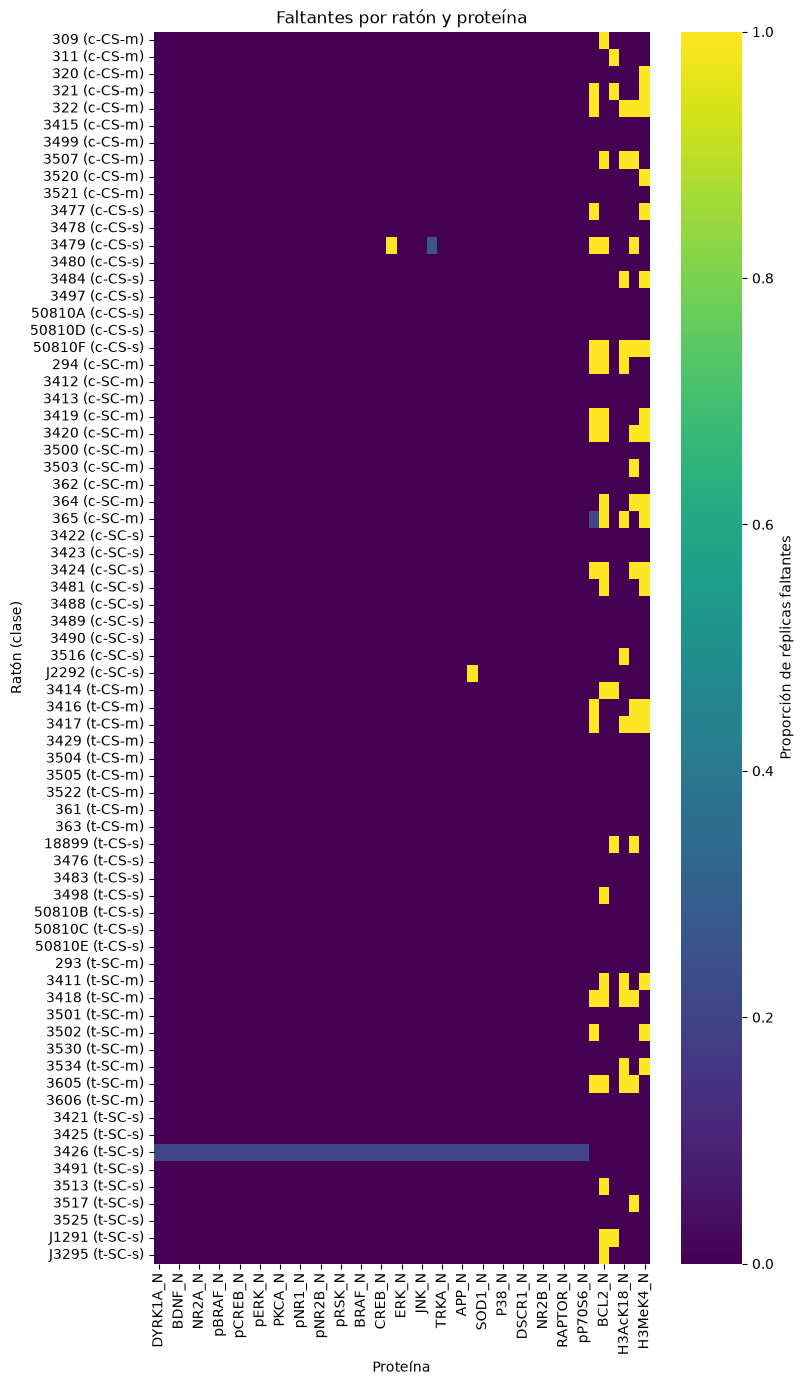

In [19]:
# Solo proteínas con algún faltante; ratones ordenados por clase
cols_na = na.columns[na.any()]
orden = df.drop_duplicates("raton").sort_values(["class", "raton"])["raton"]
prop_na = na[cols_na].groupby(df["raton"]).mean().loc[orden]

# Etiqueta de fila "ratón (clase)" para identificar la clase de cada bloque
clase_raton = df.drop_duplicates("raton").set_index("raton").loc[orden, "class"]
prop_na.index = [f"{r} ({c})" for r, c in zip(prop_na.index, clase_raton)]

fig, ax = plt.subplots(figsize=(8, 16))
sns.heatmap(prop_na, cmap="viridis", vmin=0, vmax=1, yticklabels=True,
            cbar_kws={"label": "Proporción de réplicas faltantes"}, ax=ax)
ax.set(title="Faltantes por ratón y proteína", xlabel="Proteína", ylabel="Ratón (clase)")

plt.savefig(FIGURAS / "faltantes_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** El mapa confirma los dos mecanismos de la sección 3.2. Por un lado, los bloques amarillos se concentran en las columnas de `BAD_N`, `BCL2_N`, `pCFOS_N`, `H3AcK18_N`, `EGR1_N` y `H3MeK4_N`, y cada uno ocupa todas las réplicas de un ratón; además, aparecen en ratones de todas las clases. Por otro lado, el ratón 3426 forma una franja horizontal de baja intensidad (3 de 15 réplicas) que abarca la mayoría de las proteínas. Fuera de estos dos patrones, solo aparecen dos casos parciales (`BAD_N` en el ratón 365 y `MEK_N` en el 3479).

### 3.5 ¿La ausencia en bloque se asocia con la clase?

Se cuenta, para cada proteína con ausencia en bloque, cuántos ratones de cada clase la presentan. Si la ausencia
se concentra en alguna clase, un indicador de faltante permitiría al modelo identificar la clase a partir del
proceso de medición y no de la biología, lo que constituiría fuga de información (Kuhn & Johnson, 2019). Si se
distribuye entre clases sin patrón, el faltante puede tratarse como técnico.

In [20]:
# Ratones con cada proteína ausente en bloque, por clase
clase_por_raton = df.groupby("raton")["class"].first()
bloques = na.groupby(df["raton"]).all()
display(bloques.loc[:, bloques.any()].groupby(clase_por_raton).sum())
# Proporción de ratones de cada clase con la proteína ausente en bloque
ratones_por_clase = clase_por_raton.value_counts()
display((bloques.loc[:, bloques.any()].groupby(clase_por_raton).sum()
        .div(ratones_por_clase, axis=0)
        .round(2)))
print(f"Proteínas con ausencia en bloque: {bloques.any().sum()}")
print(f"Ratones con al menos una proteína en bloque: {bloques.any(axis=1).sum()}")

,ELK_N,Bcatenin_N,BAD_N,BCL2_N,pCFOS_N,H3AcK18_N,EGR1_N,H3MeK4_N
class,,,,,,,,
c-CS-m,0,0,2,2,2,2,2,4
c-CS-s,1,0,3,2,0,2,2,3
c-SC-m,0,0,3,5,0,2,3,4
c-SC-s,0,1,1,2,0,1,1,2
t-CS-m,0,0,2,1,1,1,2,2
t-CS-s,0,0,0,1,1,0,1,0
t-SC-m,0,0,3,3,0,4,2,3
t-SC-s,0,0,0,3,1,0,1,0


,ELK_N,Bcatenin_N,BAD_N,BCL2_N,pCFOS_N,H3AcK18_N,EGR1_N,H3MeK4_N
class,,,,,,,,
c-CS-m,0.00,0.00,0.20,0.20,0.20,0.20,0.20,0.40
c-CS-s,0.11,0.00,0.33,0.22,0.00,0.22,0.22,0.33
c-SC-m,0.00,0.00,0.30,0.50,0.00,0.20,0.30,0.40
c-SC-s,0.00,0.11,0.11,0.22,0.00,0.11,0.11,0.22
t-CS-m,0.00,0.00,0.22,0.11,0.11,0.11,0.22,0.22
t-CS-s,0.00,0.00,0.00,0.14,0.14,0.00,0.14,0.00
t-SC-m,0.00,0.00,0.33,0.33,0.00,0.44,0.22,0.33
t-SC-s,0.00,0.00,0.00,0.33,0.11,0.00,0.11,0.00


Proteínas con ausencia en bloque: 8
Ratones con al menos una proteína en bloque: 35


**Interpretación:** Las 8 proteínas con ausencia en bloque afectan a 35 ratones, repartidos entre las ocho clases y los dos genotipos. Ninguna proteína falta solo en una clase, y las proporciones por clase son bajas y parecidas (el máximo es 0,50 en `BCL2_N` para `c-SC-m`, con solo 10 ratones en esa clase). En consecuencia, no se observa que la ausencia dependa de la condición experimental, lo que es coherente con un faltante de origen técnico, es decir, proteínas que no se midieron en ciertos ratones, y no con un faltante que dependa del propio nivel de expresión (Little & Rubin, 2019). Con todo, este análisis no permite probar formalmente que el mecanismo sea aleatorio, de modo que se trata de una conclusión descriptiva.

### 3.6 Mecanismos identificados y decisiones

| Mecanismo | Afecta a | Decisión | Justificación |
|---|---|---|---|
| Proteínas ausentes en todas las réplicas de un ratón | 8 proteínas en 35 ratones | Mantener las proteínas e imputar con k vecinos más cercanos dentro del `Pipeline` | Los faltantes ocurren en bloques que abarcan las 15 réplicas de un ratón y, además, no se asocian con una clase específica (sección 3.5); en consecuencia, corresponden a proteínas no medidas y no a una ausencia biológica. Por esta razón se descarta la imputación por mediana, ya que en proteínas como `BCL2_N`, con 26 % de faltantes, concentraría una cuarta parte de los datos en un solo valor. En su lugar, la imputación por vecinos estima cada valor a partir de los ratones con un perfil de expresión similar (Troyanskaya et al., 2001) y, al ajustarse solo con datos de entrenamiento dentro del `Pipeline`, evita la fuga de información (Kuhn & Johnson, 2019). |
| Réplicas con la mayoría de proteínas vacías (ratón 3426) | 3 filas | Eliminar las 3 réplicas | Las otras 12 réplicas del mismo ratón tienen esas proteínas medidas, de modo que el faltante no responde a la condición biológica del individuo sino a una falla técnica de esas mediciones. Además, imputar más de la mitad de una fila equivaldría a fabricar la observación, y eliminarla conserva al ratón con 12 réplicas completas. |
| Columnas duplicadas `ARC_N` / `pS6_N` | 1 variable | Eliminar `pS6_N` | Ambas columnas tienen valores idénticos en las 1.080 filas, lo que indica una duplicación en la base original. En consecuencia, no es posible saber a qué proteína corresponden los valores, por lo que `ARC_N` se conserva pero sin interpretación biológica confiable. |

Las decisiones se registran en `docs/bitacora_decisiones.md`.

## 4. Valores atípicos

Se identifican atípicos univariados con la regla de Tukey: un valor es atípico si está por debajo de
Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR (Tukey, 1977). La regla se aplica dos veces, sobre toda la base y dentro
de cada clase, para distinguir valores realmente extremos de diferencias esperables entre grupos experimentales.

### 4.1 Detección global y dentro de cada clase

In [21]:
def mascara_atipicos(x, k=1.5):
    """Marca como True los valores fuera de [Q1 - k * IQR, Q3 + k * IQR] (Regla de Tukey)"""
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    return (x < q1 - k * iqr) | (x > q3 + k * iqr)

# Máscaras del mismo tamaño que df[proteinas]: True = valor atípico
atip_global = df[proteinas].apply(mascara_atipicos)
atip_clase = df.groupby("class")[proteinas].transform(mascara_atipicos)

conteo_atipicos = pd.DataFrame({
    "global": atip_global.sum(),
    "dentro_clase": atip_clase.sum(),
    "solo_global": (atip_global & ~atip_clase).sum(),
}).sort_values("global", ascending=False)

print(f"Celdas atípicas (global): {atip_global.sum().sum()} | dentro de clase: {atip_clase.sum().sum()}")
conteo_atipicos.head(15)

Celdas atípicas (global): 1551 | dentro de clase: 1774


,global,dentro_clase,solo_global
AcetylH3K9_N,76,90,39
Tau_N,73,69,47
BRAF_N,69,46,39
DSCR1_N,57,51,12
DYRK1A_N,48,28,25
ITSN1_N,44,22,26
RRP1_N,43,46,14
pELK_N,41,47,15
ELK_N,39,27,24
pERK_N,36,38,13


**Interpretación:** La regla de Tukey marca más celdas dentro de cada clase (1.774) que sobre la base completa (1.551). Esto ocurre porque cada clase tiene un rango más estrecho que la base completa, de modo que valores que se confunden con las otras clases a nivel global resultan extremos dentro de su propio grupo. A la inversa, parte de los atípicos globales deja de serlo dentro de la clase (columna `solo_global`), lo que indica diferencias reales entre grupos; esta distinción se cuantifica en la sección 4.5.

### 4.2 Distribución por clase de las proteínas con más atípicos

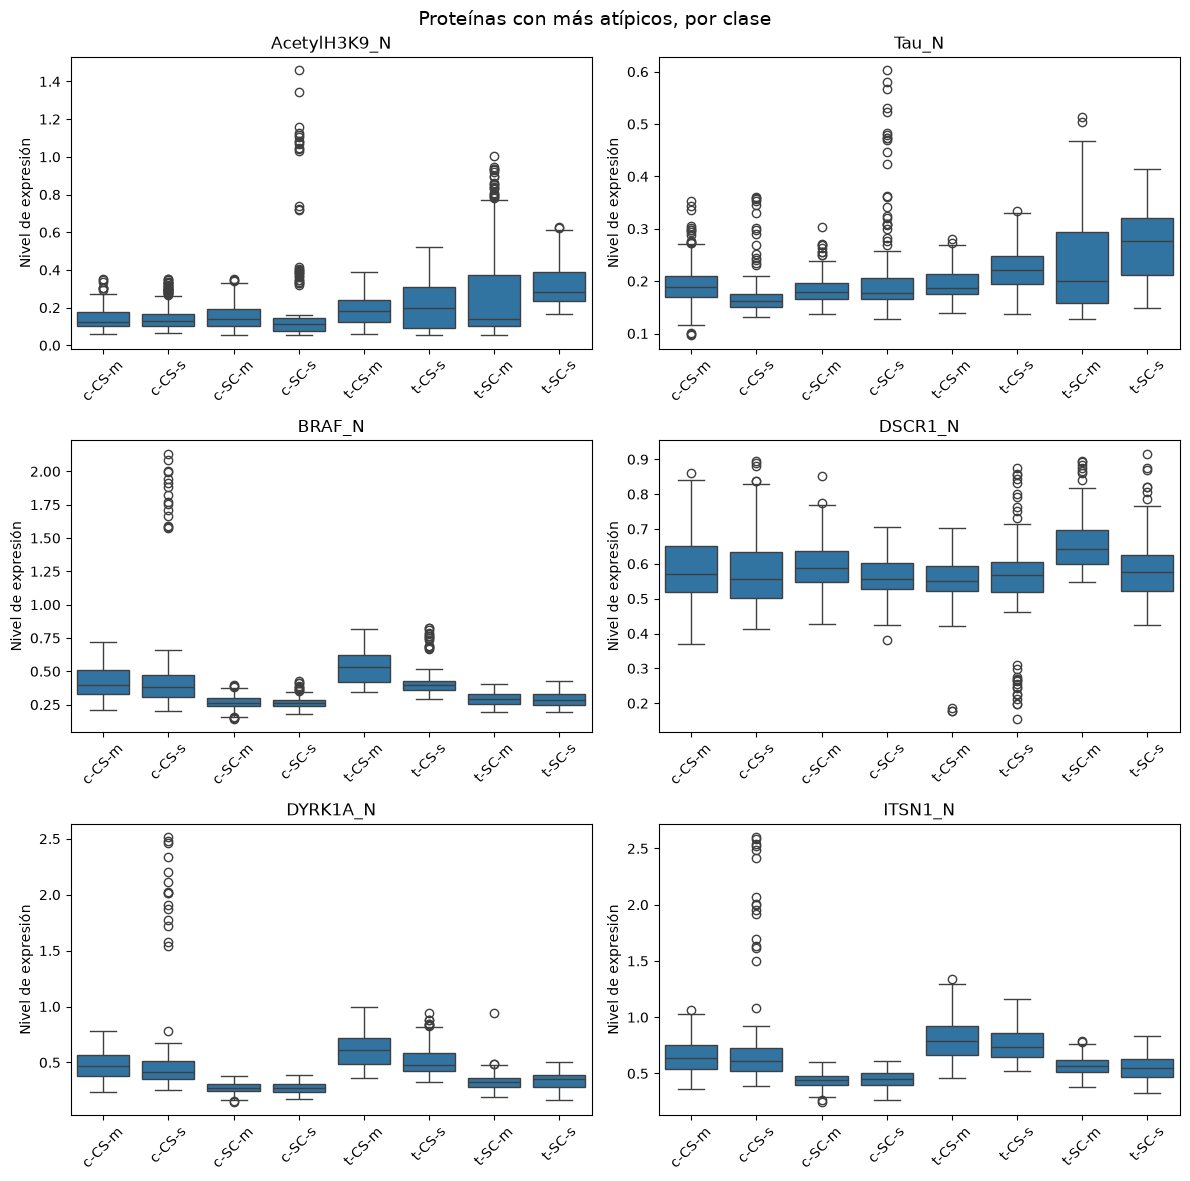

In [22]:
proteinas_seleccionadas = conteo_atipicos.head(6).index
orden_clases = sorted(df["class"].unique())

fig, axs = plt.subplots(3, 2, figsize=(12, 12))
for ax, proteina in zip(axs.flat, proteinas_seleccionadas):
    sns.boxplot(data=df, x="class", y=proteina, order=orden_clases, ax=ax)
    ax.set(title=proteina, xlabel="", ylabel="Nivel de expresión")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Proteínas con más atípicos, por clase", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS / "atipicos_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** Los atípicos no se reparten de forma homogénea entre clases. En `BRAF_N`, `DYRK1A_N` e `ITSN1_N`, los valores extremos se concentran en `c-CS-s` y forman un grupo separado (entre 1,5 y 2,5), muy por encima del resto de la clase; además, estas tres proteínas tienen niveles más altos en las clases CS (estimuladas para aprender) que en las SC (Higuera et al., 2015). En `AcetylH3K9_N`, los extremos aparecen sobre todo en `c-SC-s` y `t-SC-m`, mientras que `DSCR1_N` presenta atípicos en ambas colas dentro de `t-CS-s`. En consecuencia, buena parte de los atípicos parece corresponder a ratones concretos dentro de una clase, lo que se verifica en la sección 4.3.

### 4.3 ¿Réplica aislada o ratón completo?

Para cada ratón y proteína se cuenta en cuántas de sus 15 réplicas el valor es atípico dentro de su clase. Un
atípico en una sola réplica sugiere ruido técnico de esa medición; un atípico en la mayoría de las réplicas
indica que el ratón completo es distinto.

In [23]:
# Réplicas atípicas por ratón y proteína (0 a 15)
replicas_atipicas = atip_clase.groupby(df["raton"]).sum()

# Ratones con más celdas atípicas en total
replicas_atipicas.sum(axis=1).sort_values(ascending=False).head(10)

raton
3484      105
J2292      96
3516       86
18899      76
3418       70
3483       70
3497       52
3424       50
3420       50
50810A     44
dtype: int64

**Interpretación:** Los atípicos se concentran en pocos individuos: el ratón 3484 acumula 105 celdas atípicas, seguido por J2292 (96) y 3516 (86). Esto confirma que el patrón observado en los boxplots responde a ratones completos y no a mediciones sueltas.

### 4.4 Atípicos en la relación entre dos proteínas

Algunos valores no son extremos en ninguna proteína por separado, pero sí en su combinación. Se grafica un par
de proteínas que presentan atípicos en la misma clase y se resalta el ratón con más réplicas atípicas.

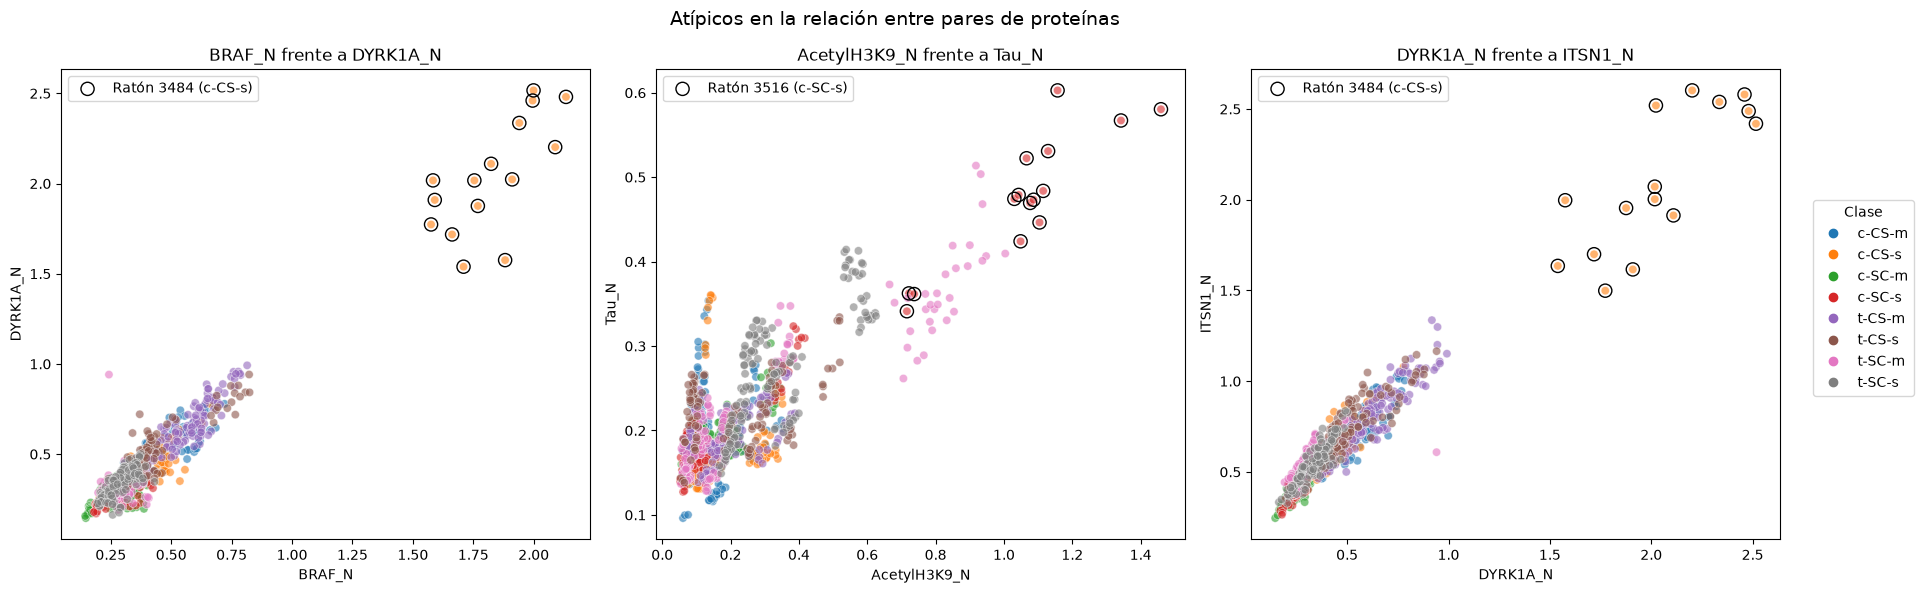

In [24]:
# Pares de proteínas a comparar: (eje x, eje y)
pares = [
    ("BRAF_N", "DYRK1A_N"),
    ("AcetylH3K9_N", "Tau_N"),
    ("DYRK1A_N", "ITSN1_N"),
]

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

for ax, (prot_x, prot_y) in zip(axs, pares):
    # Ratón con más réplicas atípicas en las dos proteínas del par
    raton_destacado = replicas_atipicas[[prot_x, prot_y]].sum(axis=1).idxmax()
    destacado = df[df["raton"] == raton_destacado]

    sns.scatterplot(data=df, x=prot_x, y=prot_y, hue="class", hue_order=orden_clases,
                    alpha=0.6, legend=False, ax=ax)
    ax.scatter(destacado[prot_x], destacado[prot_y],
               facecolors="none", edgecolors="black", s=90,
               label=f"Ratón {raton_destacado} ({destacado["class"].iloc[0]})")
    ax.set(title=f"{prot_x} frente a {prot_y}", xlabel=prot_x, ylabel=prot_y)
    ax.legend(loc="upper left")

# Leyenda de clases compartida
colores = sns.color_palette(n_colors=len(orden_clases))
marcadores = [plt.Line2D([], [], marker="o", linestyle="", color=c) for c in colores]
fig.legend(marcadores, orden_clases, title="Clase", loc="center right", bbox_to_anchor=(1.07, 0.5))

fig.suptitle("Atípicos en la relación entre pares de proteínas", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS / "atipicos_dispersion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** El ratón 3484 (`c-CS-s`) forma un grupo claramente separado en `BRAF_N`/`DYRK1A_N` y en `DYRK1A_N`/`ITSN1_N`, pero se ubica sobre la prolongación de la tendencia del resto de los ratones. Es decir, este ratón tiene niveles altos en las tres proteínas al mismo tiempo y conserva la relación entre ellas, lo que es más coherente con una expresión biológica coordinada que con un error de medición, que afectaría a una sola proteína. En cambio, el ratón 3516 (`c-SC-s`) ocupa el extremo superior de `AcetylH3K9_N`/`Tau_N`, pero en continuidad con los ratones de `t-SC-m`, de modo que su posición es extrema sin estar aislada.

### 4.5 Clasificación de los atípicos

Cada celda atípica se asigna a una de tres categorías:

- **Fenómeno de subgrupo:** atípico en la base completa, pero no dentro de su clase.
- **Ratón excepcional:** atípico dentro de su clase en al menos `UMBRAL_RATON` de las 15 réplicas del ratón.
- **Réplica aislada:** atípico dentro de su clase en pocas réplicas del ratón (posible error técnico).

In [25]:
# Mayoría de las 15 réplicas: a partir de aquí el ratón completo se considera distinto
UMBRAL_RATON = 8

# Para cada celda, cuántas réplicas de su ratón son atípicas en esa proteína 
n_rep_atipicas = atip_clase.groupby(df["raton"]).transform("sum")

casos_atipicos = pd.DataFrame({
    "subgrupo": (atip_global & ~atip_clase).sum(),
    "raton_excepcional": (atip_clase & (n_rep_atipicas >= UMBRAL_RATON)).sum(),
    "replica_aislada": (atip_clase & (n_rep_atipicas < UMBRAL_RATON)).sum(),
})

print("Total por categoría")
print(casos_atipicos.sum())

display(casos_atipicos.sort_values("raton_excepcional", ascending=False).head(15))

Total por categoría
subgrupo              757
raton_excepcional     507
replica_aislada      1267
dtype: int64


,subgrupo,raton_excepcional,replica_aislada
AcetylH3K9_N,39,78,12
pP70S6_N,7,52,7
Tau_N,47,42,27
S6_N,0,35,15
BRAF_N,39,30,16
pELK_N,15,26,21
DSCR1_N,12,25,26
pPKCAB_N,0,25,17
pERK_N,13,24,14
pCAMKII_N,0,22,2


In [26]:
# Pares (ratón, proteína) donde el ratón completo es atípico
excepcionales = (replicas_atipicas >= UMBRAL_RATON).stack()
excepcionales = excepcionales[excepcionales].index.to_frame(index=False, name=["raton", "proteina"])
excepcionales = excepcionales.merge(clase_por_raton.reset_index(), on="raton")

print(f"Ratones excepcionales: {excepcionales['raton'].nunique()} | pares ratón-proteína: {len(excepcionales)}")
excepcionales

Ratones excepcionales: 20 | pares ratón-proteína: 42


,raton,proteina,class
0,18899,DSCR1_N,t-CS-s
1,18899,RAPTOR_N,t-CS-s
2,18899,BCL2_N,t-CS-s
3,293,S6_N,t-SC-m
4,293,AcetylH3K9_N,t-SC-m
5,293,H3AcK18_N,t-SC-m
6,3413,pELK_N,c-SC-m
7,3418,pP70S6_N,t-SC-m
8,3418,AcetylH3K9_N,t-SC-m
9,3419,Tau_N,c-SC-m


**Interpretación:** La mitad de las celdas atípicas (1.267) corresponde a réplicas aisladas, mientras que 757 son fenómenos de subgrupo y 507 provienen de ratones excepcionales. Estos últimos se concentran en 42 pares ratón-proteína de 20 ratones, y solo el ratón 3484 aporta 7 de ellos (sección 4.3). Además, en algunas proteínas predomina claramente una categoría: en `AcetylH3K9_N`, 78 de sus atípicos provienen de ratones excepcionales, lo que indica que su alta variabilidad (sección 2.1) se explica por pocos individuos.

### 4.6 Valores imposibles

Un nivel de expresión no puede ser cero ni negativo; un valor así corresponde a un error de registro y no a una
observación extrema, por lo que se trata aparte de las categorías de la sección 4.5.

In [27]:
# Máscara de valores imposibles (≤ 0) en formato largo: una fila por celda
es_imposible = (df[proteinas] <= 0).stack()
ubicacion = es_imposible[es_imposible].index

print(f"Valores imposibles (≤ 0): {len(ubicacion)}")

imposibles = pd.DataFrame({
    "MouseID": df.loc[ubicacion.get_level_values(0), "MouseID"].values,
    "class": df.loc[ubicacion.get_level_values(0), "class"].values,
    "proteina": ubicacion.get_level_values(1),
    "valor": [df.at[fila, proteina] for fila, proteina in ubicacion],
})
imposibles

Valores imposibles (≤ 0): 1


,MouseID,class,proteina,valor
0,365_14,c-SC-m,RRP1_N,-0.062008


**Interpretación:** Solo hay un valor imposible en toda la base: `RRP1_N` = −0,062 en la réplica 365_14 (`c-SC-m`). Al tratarse de un único caso, aislado y sin patrón, se interpreta como un error de registro.

### 4.7 Decisiones sobre los atípicos

| Categoría | Casos | Decisión | Justificación |
|---|---|---|---|
| Fenómeno de subgrupo | 757 celdas | Mantener | Estos valores son atípicos solo frente a la base completa, mientras que dentro de su clase se comportan como observaciones normales. Por tanto, reflejan diferencias reales entre los grupos experimentales, que constituyen precisamente la señal que el modelo de clasificación debe aprender; eliminarlos borraría esa diferencia. |
| Ratón excepcional | 507 celdas en 20 ratones (42 pares ratón proteína) | Mantener | El valor extremo se presenta en la mayoría de las 15 réplicas del ratón, de modo que es reproducible y no corresponde a un error aleatorio de medición. Además, como la comparación se hace dentro de la clase, la diferencia no se explica por el tratamiento ni por el entrenamiento, sino por la variabilidad propia del individuo. En consecuencia, se conserva como observación excepcional, puesto que eliminar ratones reduciría el tamaño efectivo de clases que ya son pequeñas. |
| Réplica aislada | 1.267 celdas | Mantener | La regla de 1,5·IQR marca alrededor del 0,7 % de los valores incluso en una distribución normal sin errores (Hoaglin et al., 1986), y este porcentaje aumenta en distribuciones asimétricas como las de 17 proteínas de la base (sección 2.2). Así, el volumen de casos es compatible con la variabilidad natural de las colas, y convertirlos en faltantes eliminaría variación real sin evidencia de error. |
| Valores imposibles | 1 celda (`RRP1_N`, réplica 365_14) | Reemplazar por NaN e imputar con k vecinos más cercanos dentro del `Pipeline` | Un nivel de expresión negativo es físicamente imposible, por lo que el valor corresponde a un error de registro. Dado que no es posible saber cuál era el valor original, se trata como faltante y se imputa con el mismo procedimiento de la sección 3.6, en lugar de corregirlo con un supuesto como el cambio de signo. |

## 5. Relaciones entre variables

Se usa la correlación de Spearman, basada en rangos, porque 17 proteínas presentan asimetría fuerte (sección 2.2)
y hay ratones con valores extremos (sección 4); a diferencia de Pearson, Spearman no supone linealidad ni normalidad
y es menos sensible a valores extremos (Schober et al., 2018). Se excluye una de las dos columnas duplicadas
(`ARC_N` / `pS6_N`, sección 1.4) para no introducir una correlación artificial de 1. Los faltantes se manejan
por pares: cada coeficiente usa las filas con dato en ambas proteínas.

### 5.1 Matriz de correlación entre proteínas

Se presenta la matriz de correlación de Spearman entre las 76 proteínas restantes (sin `pS6_N`). Las filas y
columnas se reordenan mediante agrupamiento jerárquico, de modo que las proteínas con patrones de correlación
similares quedan contiguas y forman bloques visibles. La escala va de −1 (azul, relación inversa) a 1 (rojo,
relación directa), con 0 en blanco (sin relación).

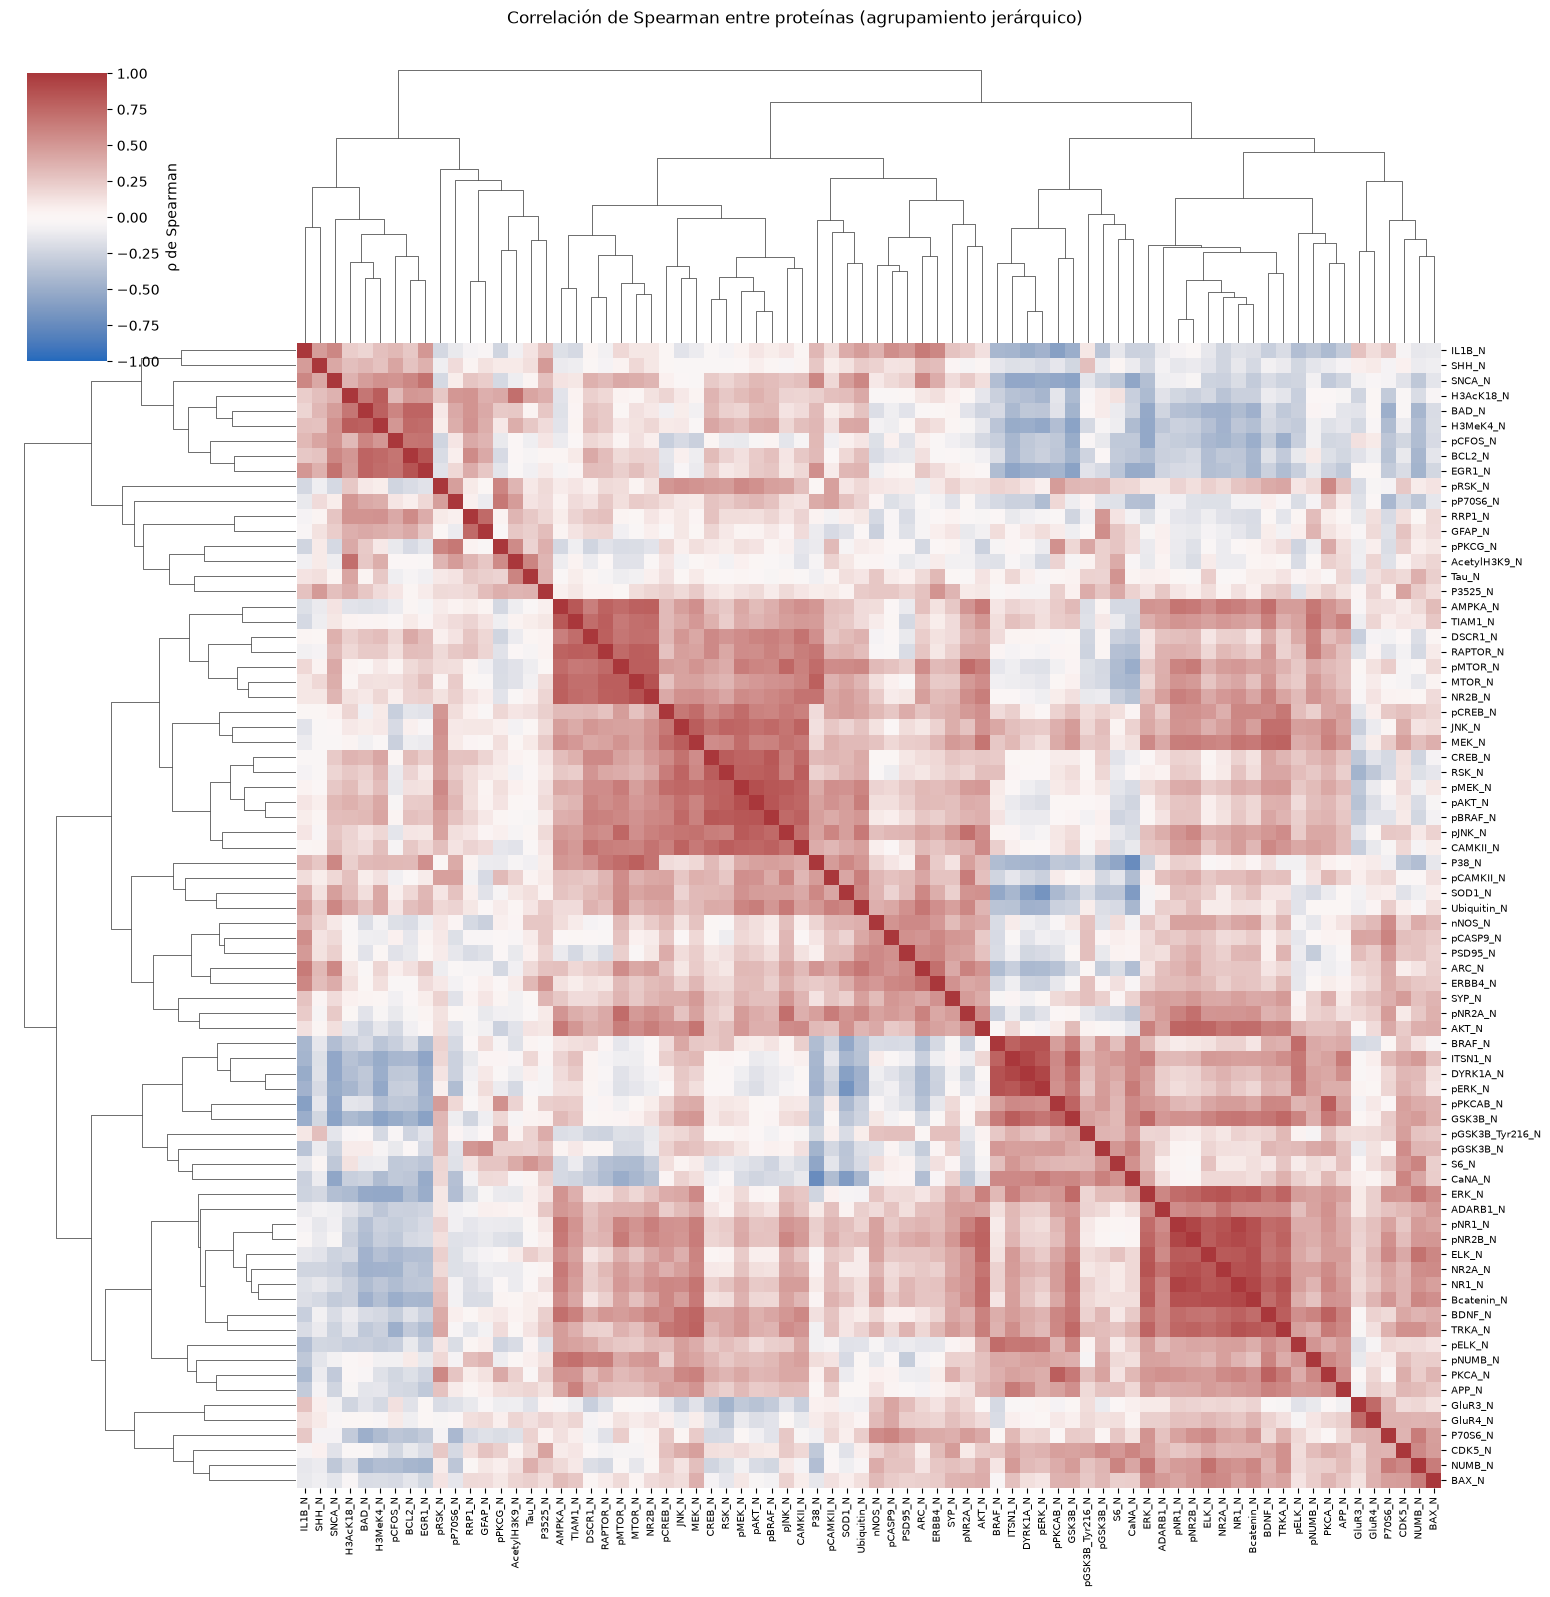

In [28]:
# Una de las columnas duplicadas se excluye (decisión registrada en la bitácora)
proteinas_corr = [p for p in proteinas if p != "pS6_N"]

matriz_correlacion = df[proteinas_corr].corr(method="spearman")

g = sns.clustermap(
    matriz_correlacion, cmap="vlag", vmin=-1, vmax=1, center=0,
    xticklabels=True, yticklabels=True, figsize=(16, 16),
    cbar_kws={"label": "ρ de Spearman"},
)
g.ax_heatmap.tick_params(labelsize=7)
g.figure.suptitle("Correlación de Spearman entre proteínas (agrupamiento jerárquico)", y=1.02)
g.savefig(FIGURAS / "correlacion_clustermap.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** El agrupamiento jerárquico revela bloques de proteínas con correlación positiva entre sí. Se distinguen, entre otros, un bloque amplio de proteínas de señalización (`MEK_N`, `pMEK_N`, `pAKT_N`, `pBRAF_N`, `RSK_N`, `CREB_N`, `MTOR_N`, `RAPTOR_N`); un bloque de proteínas del receptor NMDA y la vía ERK (`NR1_N`, `pNR1_N`, `NR2A_N`, `pNR2B_N`, `ERK_N`, `ELK_N`, `Bcatenin_N`, `BDNF_N`); y un bloque más pequeño con `BRAF_N`, `DYRK1A_N`, `ITSN1_N` y `pERK_N`. Las correlaciones negativas son menos frecuentes y se concentran entre este último bloque y un grupo formado por `BAD_N`, `BCL2_N`, `EGR1_N`, `pCFOS_N`, `H3AcK18_N` y `H3MeK4_N`. Cabe señalar que estas seis proteínas son las que tienen ausencia en bloque (sección 3.5), por lo que sus coeficientes se calculan con menos filas y deben interpretarse con más cautela. En conjunto, la existencia de bloques tan marcados anticipa la colinealidad entre predictores en las actividades 2 y 3.

### 5.2 Pares más correlacionados y efecto de las réplicas

Se comparan las correlaciones calculadas con las 1.080 filas y con los promedios de los 72 ratones. Si un par
cambia mucho entre ambas versiones, su correlación depende de la variación entre réplicas y no solo entre individuos.

In [29]:
def pares_correlacion(matriz):
    """Convierte una matriz de correlación en una serie con cada par una sola vez (sin diagonal)."""
    mascara = np.triu(np.ones(matriz.shape, dtype=bool), k=1)
    return matriz.where(mascara).stack().dropna()


matriz_correlacion_raton = df.groupby("raton")[proteinas_corr].mean().corr(method="spearman")

comparacion = pd.DataFrame({
    "rho_filas": pares_correlacion(matriz_correlacion),
    "rho_ratones": pares_correlacion(matriz_correlacion_raton),
})

comparacion["diferencia"] = comparacion["rho_ratones"] - comparacion["rho_filas"]
comparacion.index.names = ["proteina_1", "proteina_2"]

print("Pares con mayor |ρ| (filas)")
display(comparacion.reindex(comparacion["rho_filas"].abs().sort_values(ascending=False).index).head(10).round(3))

print("Pares que más cambian entre filas y ratones")
display(comparacion.reindex(comparacion["diferencia"].abs().sort_values(ascending=False).index).head(10).round(3))

Pares con mayor |ρ| (filas)


rho_filas  rho_ratones  diferencia
proteina_1 proteina_2                                    
NR1_N      pNR1_N          0.942        0.889      -0.053
DYRK1A_N   ITSN1_N         0.929        0.948       0.019
           pERK_N          0.925        0.928       0.003
pNR1_N     pNR2B_N         0.922        0.883      -0.039
NR1_N      Bcatenin_N      0.916        0.876      -0.041
           pNR2B_N         0.907        0.850      -0.057
ELK_N      Bcatenin_N      0.884        0.721      -0.163
NR2A_N     Bcatenin_N      0.883        0.728      -0.156
pAKT_N     pMEK_N          0.883        0.947       0.064
NR2A_N     pNR2B_N         0.877        0.740      -0.137

Pares que más cambian entre filas y ratones


,,rho_filas,rho_ratones,diferencia
proteina_1,proteina_2,,,
NR2A_N,P70S6_N,0.444,-0.035,-0.479
GluR4_N,BAD_N,0.007,0.450,0.442
Bcatenin_N,BAD_N,-0.483,-0.050,0.432
GluR4_N,EGR1_N,0.002,0.433,0.431
CREB_N,Bcatenin_N,0.129,0.549,0.420
Bcatenin_N,P70S6_N,0.508,0.089,-0.420
P70S6_N,EGR1_N,-0.303,0.113,0.416
pNR2B_N,EGR1_N,-0.197,0.214,0.411
P70S6_N,BCL2_N,-0.354,0.057,0.410


**Interpretación:** Los pares más correlacionados mantienen valores altos al pasar a promedios por ratón, de modo que reflejan relaciones entre individuos y no solo entre réplicas (sección 5.5). En cambio, otros pares cambian de forma marcada: por ejemplo, `NR2A_N`/`P70S6_N` pasa de 0,44 por filas a −0,04 por ratones, y `GluR4_N`/`BAD_N` pasa de 0,01 a 0,45. En el primer caso, la correlación proviene de la variación entre réplicas de un mismo ratón, lo que coincide con que `NR2A_N` sea una de las proteínas con mayor variación dentro del ratón (sección 2.3); en el segundo, la relación solo aparece entre individuos y queda oculta por el ruido de las réplicas. Además, varios de estos pares incluyen proteínas con ausencia en bloque (`BAD_N`, `BCL2_N`, `EGR1_N`), cuya correlación por ratón se calcula con menos individuos y es, por tanto, menos estable. En consecuencia, la correlación por filas no siempre representa la relación entre ratones, que es la unidad de análisis

### 5.3 ¿La correlación depende del ratón excepcional?

Se recalculan las correlaciones de los pares afectados en la sección 4 excluyendo al ratón con más réplicas atípicas.

In [30]:
raton_excluido = replicas_atipicas.sum(axis=1).idxmax()
sin_raton = df[df["raton"] != raton_excluido]

pares_revisar = [("BRAF_N", "DYRK1A_N"), ("DYRK1A_N", "ITSN1_N"), ("BRAF_N", "ITSN1_N")]

sensibilidad = pd.DataFrame([
    {
        "proteina_1": x,
        "proteina_2": y,
        "rho_con": df[x].corr(df[y], method="spearman"),
        "rho_sin": sin_raton[x].corr(sin_raton[y], method="spearman"),
        "r_pearson_con": df[x].corr(df[y]),
        "r_pearson_sin": sin_raton[x].corr(sin_raton[y]),
    }
    for x, y in pares_revisar
])

print(f"Ratón excluido: {raton_excluido}")
sensibilidad.round(3)

Ratón excluido: 3484


,proteina_1,proteina_2,rho_con,rho_sin,r_pearson_con,r_pearson_sin
0,BRAF_N,DYRK1A_N,0.862,0.856,0.960,0.908
1,DYRK1A_N,ITSN1_N,0.929,0.926,0.960,0.930
2,BRAF_N,ITSN1_N,0.776,0.766,0.918,0.834


**Interpretación:** Al excluir al ratón 3484, la correlación de Spearman apenas cambia (por ejemplo, `BRAF_N`/`ITSN1_N` pasa de 0,776 a 0,766), mientras que la de Pearson disminuye bastante más (de 0,918 a 0,834). Esto confirma que un solo ratón con valores extremos infla la correlación lineal, y justifica el uso de Spearman en esta sección (Schober et al., 2018). Asimismo, como la correlación de Spearman se mantiene alta sin este ratón, la relación entre estas proteínas no depende de él.

### 5.4 ¿La relación DYRK1A_N / ITSN1_N depende del genotipo?

Ambas proteínas están codificadas por genes del segmento triplicado en el ratón Ts65Dn (Reeves et al., 1995;
Ahmed et al., 2015). Si su correlación se debe a la dosis génica, debería disminuir al calcularla dentro de cada
genotipo. Se usan los promedios por ratón para que cada individuo cuente una sola vez.

In [31]:
medias_raton = df.groupby(["raton", "Genotype"])[["DYRK1A_N", "ITSN1_N"]].mean()

# ρ dentro de cada genotipo y con todos los ratones juntos
rho_genotipo = (medias_raton.groupby("Genotype").corr(method="spearman")
                .xs("DYRK1A_N", level=1)["ITSN1_N"])
rho_genotipo["Todos"] = medias_raton.corr(method="spearman").loc["DYRK1A_N", "ITSN1_N"]
rho_genotipo.round(3)

Genotype
Control    0.963
Ts65Dn     0.937
Todos      0.948
Name: ITSN1_N, dtype: float64

**Interpretación:** La correlación entre `DYRK1A_N` e `ITSN1_N` es prácticamente igual dentro de los controles (0,963), dentro de los trisómicos (0,937) y con todos los ratones juntos (0,948). Si la relación se debiera a la trisomía, la correlación debería disminuir al calcularla dentro de cada genotipo; como no ocurre, la hipótesis de la dosis génica no explica la correlación. Cabe distinguir, sin embargo, entre la correlación y los niveles: la trisomía podría modificar el nivel medio de ambas proteínas sin alterar su relación, y esa diferencia de niveles entre grupos es precisamente la información que se aprovechará en la clasificación de la Actividad 3.

### 5.5 Relaciones relevantes y candidata a variable dependiente

| Par / grupo | ρ filas | ρ ratones | Interpretación biológica |
|---|---|---|---|
| `NR1_N`, `pNR1_N`, `pNR2B_N` (receptor NMDA) | 0,91–0,94 | 0,85–0,89 | `NR1_N` y `pNR1_N` corresponden a la misma proteína en su forma total y fosforilada; dado que la forma fosforilada es una fracción de la total, una mayor cantidad de proteína ofrece más sustrato para la fosforilación. A su vez, NR1 (GluN1) y NR2B (GluN2B) son subunidades del mismo receptor, ya que un receptor NMDA funcional requiere GluN1 junto con una subunidad GluN2 (Paoletti et al., 2013); por ello, su abundancia varía en conjunto. Sin embargo, las tres correlaciones disminuyen al pasar a promedios por ratón, lo que indica que parte de la relación proviene de la co-variación entre réplicas de un mismo individuo. |
| `DYRK1A_N` / `ITSN1_N` | 0,93 | 0,95 | Ambas proteínas están codificadas por genes del segmento triplicado en el ratón Ts65Dn (Reeves et al., 1995; Ahmed et al., 2015), por lo que se planteó que la correlación se debía a la dosis génica. No obstante, la sección 5.4 descarta esta hipótesis, puesto que la correlación se mantiene dentro de cada genotipo (Control: 0,96; Ts65Dn: 0,94). En consecuencia, la relación refleja una co-regulación entre individuos que no depende del número de copias del gen, cuyo mecanismo no puede establecerse con estos datos. |
| `DYRK1A_N` / `pERK_N` | 0,93 | 0,93 | DYRK1A forma un complejo con Ras, B-Raf y MEK1 y potencia la activación de ERK en la cascada MAPK (Kelly & Rahmani, 2005). De manera coherente, `BRAF_N` también se correlaciona con `pERK_N` (ρ = 0,86). Además, la correlación es prácticamente igual en filas y en ratones, de modo que se trata de una relación entre individuos y no del ruido entre réplicas. |

**Candidata a variable dependiente (Actividad 2):** `pERK_N`, es decir, la forma activa de ERK y el punto final
de la cascada MAPK, con `DYRK1A_N`, `BRAF_N` e `ITSN1_N` como predictores principales (ρ entre 0,83 y 0,93). Cabe
señalar que `pMEK_N` (ρ = −0,13) y `ERK_N` (ρ = 0,47) no acompañan a `pERK_N`, a pesar de pertenecer a la misma vía,
lo que muestra que la correlación entre niveles de proteína no equivale a la secuencia de activación de la cascada.
Por otra parte, los predictores están muy correlacionados entre sí (`DYRK1A_N`/`ITSN1_N`: 0,93;
`DYRK1A_N`/`BRAF_N`: 0,86), por lo que se espera multicolinealidad; esto justifica comparar mínimos cuadrados
ordinarios con modelos regularizados (Ridge y Lasso) en la Actividad 2 (James et al., 2023).

## 6. Base depurada

En esta sección se construye la base que usarán las actividades 2 y 3, aplicando únicamente correcciones que no
requieren estimar ningún valor a partir de los datos. En primer lugar, se eliminan las 3 réplicas del ratón 3426
en las que falta la mayoría de las proteínas (sección 3.6), ya que imputarlas equivaldría a fabricar la
observación; aun así, el ratón se conserva con sus 12 réplicas completas. En segundo lugar, el único nivel de
expresión negativo (`RRP1_N`, réplica 365_14) se reemplaza por un faltante, puesto que corresponde a un error de
registro cuyo valor original no se conoce (sección 4.7). Por último, se elimina `pS6_N`, que duplica a `ARC_N`
en todas las filas (sección 3.6).

Por el contrario, los pasos que estiman algo de los datos, como la imputación con k vecinos más cercanos, el
escalado de las variables o la selección de predictores colineales, no se aplican aquí. Estos pasos se ajustan
dentro del `Pipeline` después de la partición agrupada por ratón, de modo que solo usen información del
conjunto de entrenamiento y se evite la fuga de información hacia la validación (Kuhn & Johnson, 2019).

### 6.1 Copia de trabajo

Se trabaja sobre una copia de `df` para no modificar la base que usaron las secciones anteriores; de esta forma,
el notebook puede volver a ejecutar cualquier sección sin que los cambios de la depuración alteren sus resultados.

In [32]:
df_depurado = df.copy()

# Valores de partida para verificar los cambios en la sección 6.6
filas_original = len(df)
na_original = df[proteinas].isna().sum().sum()

### 6.2 Eliminar las réplicas del ratón 3426

Se eliminan las réplicas en las que falta más de la mitad de las proteínas. En la base, el número de faltantes
por fila va de 0 a 5 y luego salta a 43, de modo que el umbral separa sin ambigüedad las 3 réplicas del ratón
3426 descritas en la sección 3.6 del resto de la base.

In [33]:
# Réplicas con más de la mitad de las proteínas sin medir
mayoria_vacia = df_depurado[proteinas].isna().sum(axis=1) > len(proteinas) / 2
replicas_eliminadas = df_depurado.loc[mayoria_vacia, "MouseID"].tolist()

assert len(replicas_eliminadas) == 3
assert (df_depurado.loc[mayoria_vacia, "raton"] == "3426").all()

df_depurado = df_depurado[~mayoria_vacia]
print(f"Réplicas eliminadas: {replicas_eliminadas}")

Réplicas eliminadas: ['3426_13', '3426_14', '3426_15']


### 6.3 Valores imposibles

El nivel de expresión mide la cantidad de una proteína en la muestra, por lo que no puede tomar valores negativos.
En consecuencia, el único valor negativo de la base (`RRP1_N`, réplica 365_14; sección 4.6) corresponde a un error
de registro y se reemplaza por un faltante, en lugar de eliminar la réplica completa. De esta forma, se conservan
las otras 76 proteínas medidas en esa réplica, y el valor se imputará dentro del `Pipeline` con el mismo
procedimiento de los demás faltantes (sección 4.7).

In [34]:
# Celdas con nivel de expresión ≤ 0 (sección 4.6)
celdas_imposibles = df_depurado[proteinas] <= 0
print(f"Celdas imposibles reemplazadas por NaN: {celdas_imposibles.sum().sum()}")

df_depurado[proteinas] = df_depurado[proteinas].mask(celdas_imposibles)

assert celdas_imposibles.sum().sum() == 1
assert not (df_depurado[proteinas] <= 0).any().any()

Celdas imposibles reemplazadas por NaN: 1


### 6.4 Eliminar `pS6_N`

Se elimina `pS6_N`, cuyos valores son idénticos a los de `ARC_N` en las 1.080 filas (sección 1.4). Conservar
ambas columnas duplicaría la misma información en el modelo; en consecuencia, se mantiene `ARC_N`, aunque sin
una interpretación biológica confiable (sección 3.6).

In [35]:
df_depurado = df_depurado.drop(columns="pS6_N")

# Lista de proteínas de la base depurada (76, sin pS6_N)
proteinas_depurado = [p for p in proteinas if p != "pS6_N"]
assert len(proteinas_depurado) == 76

### 6.5 Tipos y orden

Las variables de diseño se convierten en categorías, ya que el formato parquet conserva este tipo y evita
reconvertirlas en las actividades 2 y 3. Además, se reinicia el índice para que sea consecutivo tras la
eliminación de las réplicas del ratón 3426.

In [36]:
# Variables de diseño como categorías (parquet conserva el tipo)
df_depurado[diseno] = df_depurado[diseno].astype("category")

# Índice consecutivo tras eliminar las réplicas del 3426
df_depurado = df_depurado.reset_index(drop=True)

### 6.6 Verificaciones finales

Antes de guardar la base se comprueba que cada cambio afectó exactamente a los registros previstos y que la
depuración no alteró la integridad de los datos: identificadores únicos, etiquetas de clase completas y
ningún valor imposible.

In [37]:
# Faltantes en las réplicas eliminadas (sección 6.2)
na_eliminados = df.loc[mayoria_vacia, proteinas].isna().sum().sum()

# Dimensiones: 3 réplicas menos; una columna menos (pS6_N)
assert len(df_depurado) == filas_original - 3
assert df_depurado.shape[1] == df.shape[1] - 1
assert "pS6_N" not in df_depurado.columns

# Ratones: se conservan los 72, el 3426 con 12 réplicas
assert df_depurado["raton"].nunique() == 72
assert (df_depurado["raton"] == "3426").sum() == 12

# Faltantes: menos los de las réplicas eliminadas, más el valor imposible
assert df_depurado[proteinas_depurado].isna().sum().sum() == na_original - na_eliminados + 1

# Integridad: identificador único, etiquetas completas, sin valores imposibles
assert df_depurado["MouseID"].is_unique
assert df_depurado[diseno].notna().all().all()
assert not (df_depurado[proteinas_depurado] <= 0).any().any()

print(f"Base depurada: {df_depurado.shape} | faltantes: {na_original} → "
      f"{df_depurado[proteinas_depurado].isna().sum().sum()}")


Base depurada: (1077, 83) | faltantes: 1396 → 1268


### 6.7 Guardar la base depurada

La base se guarda en formato parquet, que conserva los tipos de datos (incluidas las categorías de las variables
de diseño), a diferencia de CSV. Después se vuelve a leer con la función que usarán las actividades 2 y 3, para
comprobar que el archivo guardado coincide con la base construida. El archivo no se sube al repositorio
(`datos/procesados` está en `.gitignore`), por lo que se regenera al ejecutar este notebook completo.

In [38]:
ARCHIVO_DEPURADO.parent.mkdir(parents=True, exist_ok=True)
df_depurado.to_parquet(ARCHIVO_DEPURADO, index=False)

# Lectura de control con la misma función que usarán las actividades 2 y 3
df_verificacion = cargar_depurados()
pd.testing.assert_frame_equal(df_depurado, df_verificacion)

print(f"Guardado en: {ARCHIVO_DEPURADO.relative_to(ARCHIVO_DEPURADO.parents[2]).as_posix()}")
print(f"Dimensiones: {df_verificacion.shape}")

Guardado en: datos/procesados/mice_depurado.parquet
Dimensiones: (1077, 83)


### 6.8 Resumen de la depuración

Se comparan la base original y la depurada para dejar constancia del efecto de cada decisión.

In [39]:
def resumen_base(data, columnas_proteinas):
    """Dimensiones, ratones y faltantes de una versión de la base."""
    return {
        "filas": len(data),
        "columnas": data.shape[1],
        "proteinas": len(columnas_proteinas),
        "ratones": data["raton"].nunique(),
        "celdas_faltantes": data[columnas_proteinas].isna().sum().sum(),
    }

resumen_depuracion = pd.DataFrame({
    "original": resumen_base(df, proteinas),
    "depurada": resumen_base(df_depurado, proteinas_depurado),
})
resumen_depuracion["cambio"] = resumen_depuracion["depurada"] - resumen_depuracion["original"]
resumen_depuracion

,original,depurada,cambio
filas,1080,1077,-3
columnas,84,83,-1
proteinas,77,76,-1
ratones,72,72,0
celdas_faltantes,1396,1268,-128


**Cambios aplicados**

| Cambio | Registros afectados | Sección |
|---|---|---|
| Eliminación de réplicas con más de la mitad de las proteínas sin medir | 3 filas (ratón 3426) | 3.6 |
| Valor imposible reemplazado por faltante | 1 celda (`RRP1_N`, 365_14) | 4.6 – 4.7 |
| Eliminación de columna duplicada | 1 columna (`pS6_N`) | 1.4, 3.6 |

**Pendiente para el `Pipeline` (actividades 2 y 3):** imputación de los faltantes con k vecinos más cercanos,
escalado de las variables y tratamiento de la colinealidad (Dormann et al., 2013), todos ajustados solo con el
conjunto de entrenamiento de una partición agrupada por ratón. La base depurada conserva `raton` para construir 
esa partición.

## Referencias

Abdi, H. (2010). Coefficient of variation. En N. J. Salkind (Ed.), Encyclopedia of research design (pp. 169–171). SAGE.

Ahmed, M. M., Dhanasekaran, A. R., Block, A., Tong, S., Costa, A. C. S., Stasko, M., & Gardiner, K. J. (2015). Protein dynamics associated with failed and rescued learning in the Ts65Dn mouse model of Down syndrome. PLOS ONE, 10(3), e0119491. https://doi.org/10.1371/journal.pone.0119491

Bulmer, M. G. (1979). Principles of statistics. Dover.

Dormann, C. F., Elith, J., Bacher, S., Buchmann, C., Carl, G., Carré, G., Marquéz, J. R. G., Gruber, B., Lafourcade, B., Leitão, P. J., Münkemüller, T., McClean, C., Osborne, P. E., Reineking, B., Schröder, B., Skidmore, A. K., Zurell, D., & Lautenbach, S. (2013). Collinearity: A review of methods to deal with it and a simulation study evaluating their performance. Ecography, 36(1), 27–46. https://doi.org/10.1111/j.1600-0587.2012.07348.x

Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). Self-organizing feature maps identify proteins critical to learning in a mouse model of Down syndrome. PLOS ONE, 10(6), e0129126. https://doi.org/10.1371/journal.pone.0129126

Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). Mice Protein Expression [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C50S3Z

Hoaglin, D. C., Iglewicz, B., & Tukey, J. W. (1986). Performance of some resistant rules for outlier labeling. Journal of the American Statistical Association, 81(396), 991–999.

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An introduction to statistical learning: With applications in Python. Springer.

Kelly, P. A., & Rahmani, Z. (2005). DYRK1A enhances the mitogen-activated protein kinase cascade in PC12 cells by forming a complex with Ras, B-Raf, and MEK1. Molecular Biology of the Cell, 16(8), 3562–3573.

Kuhn, M., & Johnson, K. (2019). Feature engineering and selection: A practical approach for predictive models. CRC Press.

Little, R. J. A., & Rubin, D. B. (2019). Statistical analysis with missing data (3.ª ed.). Wiley.

Paoletti, P., Bellone, C., & Zhou, Q. (2013). NMDA receptor subunit diversity: Impact on receptor properties, synaptic plasticity and disease. Nature Reviews Neuroscience, 14(6), 383–400.

Reeves, R. H., Irving, N. G., Moran, T. H., Wohn, A., Kitt, C., Sisodia, S. S., Schmidt, C., Bronson, R. T., & Davisson, M. T. (1995). A mouse model for Down syndrome exhibits learning and behaviour deficits. Nature Genetics, 11(2), 177–184.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. Ecography, 40(8), 913–929.

Schober, P., Boer, C., & Schwarte, L. A. (2018). Correlation coefficients: Appropriate use and interpretation. Anesthesia & Analgesia, 126(5), 1763–1768.

Troyanskaya, O., Cantor, M., Sherlock, G., Brown, P., Hastie, T., Tibshirani, R., Botstein, D., & Altman, R. B. (2001). Missing value estimation methods for DNA microarrays. Bioinformatics, 17(6), 520–525.

Tukey, J. W. (1977). Exploratory data analysis. Addison-Wesley.